# Analizador de Opiniones sobre Universidades Peruanas
**PC3 - Procesamiento de Lenguaje Natural**

### Descripción del problema:

En el Perú hay muchas universidades, y los estudiantes que quieren elegir una
suelen guiarse por opiniones sueltas de redes sociales o de Google Maps.
Leer cientos de comentarios uno por uno toma mucho tiempo y es difícil saber
qué dice la mayoría.

**El problema:** los estudiantes peruanos no cuentan con una herramienta que les
permita ver rápidamente qué opinan los demás sobre cada universidad, qué temas
se repiten (profesores, infraestructura, costos) y si el tono general es
positivo o negativo.

**La solución:** una aplicación que recibe comentarios, los limpia, y los analiza
con PLN.

```
Comentarios (Excel)  →  Preprocesamiento  →  Sentimiento + TF-IDF + Temas  →  App en Streamlit
```

## Instalación de librerías

Correr esto una sola vez. Si ya están instaladas se puede saltar.

In [1]:
!pip install spacy pysentimiento nltk pandas openpyxl scikit-learn matplotlib wordcloud -q
!python -m spacy download es_core_news_sm -q

print("listo")

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
listo


## Imports

Usamos las siguientes librerías:
- `pandas` para leer y manejar el Excel con los comentarios
- `spaCy` para la lematización
- `nltk` para tokenizar, stopwords y stemming
- `pysentimiento` para el análisis de sentimiento en español
- `scikit-learn` para TF-IDF y modelado de temas (NMF)
- `matplotlib` y `wordcloud` para los gráficos

In [2]:
import re
import string
from collections import Counter

import nltk
import pandas as pd
import spacy
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from pysentimiento import create_analyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

print("imports ok")

imports ok


## Carga de modelos

Cargamos spaCy con el modelo en español (`es_core_news_sm`) y el analizador de sentimiento de pysentimiento. Ambos tardan un poco la primera vez.

In [3]:
nlp = spacy.load("es_core_news_sm")
analizador_sentimiento = create_analyzer(task="sentiment", lang="es")

print("modelos cargados")

config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

modelos cargados


---
## Fase 1: Recolección de datos

Los datos son comentarios de estudiantes sobre universidades peruanas, recolectados de reseñas de Google Maps (y otras fuentes como Reddit o Facebook). Los guardamos en un Excel con estas columnas:

- `id`: número de cada comentario
- `universidad`: nombre o siglas de la universidad
- `comentario`: el texto de la opinión
- `estrellas`: puntaje de 1 a 5 (vacío si la fuente no tiene estrellas)
- `fuente`: de dónde se sacó el comentario

Con `pandas` leemos el archivo, eliminamos las filas sin comentario y los comentarios repetidos.

In [16]:
def cargar_comentarios(ruta: str) -> pd.DataFrame:
    if ruta.endswith(".csv"):
        df = pd.read_csv(ruta)
    else:
        df = pd.read_excel(ruta)

    df.columns = df.columns.str.strip().str.lower()   # quita espacios y pasa a minúscula

    df = df.dropna(subset=["comentario"])             # quita filas sin comentario
    df["comentario"] = df["comentario"].astype(str).str.strip()
    df = df[df["comentario"] != ""]
    df = df.drop_duplicates(subset=["comentario"])    # quita repetidos
    return df.reset_index(drop=True)

In [17]:
from google.colab import files

archivo = files.upload()               # aparece un botón para subir el Excel
nombre_archivo = list(archivo.keys())[0]

df = cargar_comentarios(nombre_archivo)

print(f"Total de comentarios: {len(df)}")
print("\nComentarios por universidad:")
print(df["universidad"].value_counts())
print("\nPrimeras filas:")
df.head()

Saving reseñas universidades.xlsx to reseñas universidades (1).xlsx
Total de comentarios: 198

Comentarios por universidad:
universidad
Universidad Nacional Mayor de San Marcos (UNMSM)    30
Universidad Nacional Agraria La Molina (UNALM)      30
Pontificia Universidad Católica del Perú (PUCP)     30
Universidad Nacional de Ingeniería (UNI)            29
Universidad Peruana Cayetano Heredia                20
Universidad ESAN                                    20
Universidad del Pacífico                            20
Universidad de Lima                                 19
Name: count, dtype: int64

Primeras filas:


,id,universidad,comentario,estrellas,fuente
0,1,Universidad de Lima,Me sorprendió después de bastante tiempo en qu...,5.0,Google Maps
1,2,Universidad de Lima,Una universidad prestigiosa. Tiene una amplia ...,5.0,Google Maps
2,3,Universidad de Lima,"Cambió mucho su forma de acceso, ya no existen...",3.0,Google Maps
3,4,Universidad de Lima,Un ambiente de estudio que busca darles a los ...,5.0,Google Maps
4,5,Universidad de Lima,"Excelentes ambientes, comodidad y excelentes d...",5.0,Google Maps


---
## Fase 2: Preprocesamiento

Antes de aplicar las técnicas de PLN hay que limpiar los comentarios. Las reseñas tienen enlaces, números, emojis, signos de puntuación y palabras como "de", "la", "que" que no aportan información útil. El preprocesamiento elimina todo eso.

Aplicamos 6 pasos a **cada comentario**:

1. **Limpieza**: sacamos URLs, emails, números y puntuación con expresiones regulares
2. **Tokenización**: dividimos el texto en palabras individuales
3. **Stopwords**: filtramos las palabras vacías del español (y palabras como "universidad", que aparecen en todos lados)
4. **Lematización**: reducimos cada palabra a su forma base ("enseñando" → "enseñar")
5. **Stemming**: recortamos las palabras a su raíz, más agresivo que el lema
6. **Normalización**: quitamos tildes y pasamos todo a minúsculas

**Importante:** para el análisis de sentimiento usaremos el comentario original, porque palabras como "no" cambian el sentido ("no me gusta"). El texto procesado se usa para TF-IDF y temas.

In [18]:
# Stopwords del español + palabras que no aportan en este tema
STOPS = set(stopwords.words("spanish")) | {"universidad", "universidades", "u", "q", "xq", "pq"}
STEMMER = SnowballStemmer("spanish")

# 1. Limpieza
def limpiar_texto(texto: str) -> str:
    texto = re.sub(r"http\S+|www\S+", "", texto)           # URLs
    texto = re.sub(r"\S+@\S+", "", texto)                  # emails
    texto = re.sub(r"\d+", "", texto)                      # números
    texto = re.sub(r"[^\w\sáéíóúñüÁÉÍÓÚÑÜ]", " ", texto)  # puntuación y emojis
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

# 2. Tokenización
def tokenizar(texto: str) -> list:
    return word_tokenize(texto.lower(), language="spanish")

# 3. Stopwords
def eliminar_stopwords(tokens: list) -> list:
    return [t for t in tokens if t not in STOPS and t not in string.punctuation]

# 4. Lematización con spaCy
def lematizar(texto: str, nlp) -> list:
    doc = nlp(texto)
    lemas = [t.lemma_.lower() for t in doc if not t.is_stop and not t.is_punct and not t.is_space]
    return [l for l in lemas if l not in STOPS]

# 5. Stemming con Snowball
def stemming(tokens: list) -> list:
    return [STEMMER.stem(t) for t in tokens]

# 6. Normalización
def normalizar(texto: str) -> str:
    reemplazos = {"á":"a","é":"e","í":"i","ó":"o","ú":"u","ü":"u","ñ":"n"}
    for k, v in reemplazos.items():
        texto = texto.replace(k, v)
    return texto.lower()

print("funciones definidas")

funciones definidas


In [19]:
def preprocesar(texto: str, nlp) -> dict:
    limpio    = limpiar_texto(texto)
    tokens    = tokenizar(limpio)
    sin_stops = eliminar_stopwords(tokens)
    lemas     = lematizar(limpio, nlp)
    stems     = stemming(sin_stops)
    normal    = normalizar(limpio)
    return {
        "texto_limpio":         limpio,
        "tokens":               tokens,
        "tokens_sin_stopwords": sin_stops,
        "lemas":                lemas,
        "stems":                stems,
        "texto_normalizado":    normal,
    }

# Aplicamos el pipeline a cada comentario
resultados = df["comentario"].apply(lambda t: preprocesar(t, nlp))

df["texto_limpio"]         = resultados.apply(lambda r: r["texto_limpio"])
df["tokens_sin_stopwords"] = resultados.apply(lambda r: r["tokens_sin_stopwords"])
df["lemas"]                = resultados.apply(lambda r: r["lemas"])
df["stems"]                = resultados.apply(lambda r: r["stems"])
df["texto_normalizado"]    = resultados.apply(lambda r: r["texto_normalizado"])

# Texto listo para TF-IDF y temas: los lemas unidos en una sola frase
df["texto_proc"] = df["lemas"].apply(lambda l: " ".join(l))

# Quitamos comentarios que quedaron vacíos (por ejemplo, los que eran solo emojis)
df = df[df["texto_proc"].str.strip() != ""].reset_index(drop=True)

print("preprocesamiento listo para", len(df), "comentarios")

preprocesamiento listo para 198 comentarios


Comentario original:
Me sorprendió después de bastante tiempo en que no veo esta universidad, justo llegué cuando estaban preparando el terreno para los nuevos edificios. Ahora sobre la universidad actualmente, lo de siempre, infraestructura excelente, las guías, los espacios recreativos y la variedad de opciones que encuentras si quieres comer algo. Una de las más completas en los aspectos mencionados anteriormente, por no decir la mejor. Se siente como en otro lugar fuera de Perú vaya.

Texto limpio:
Me sorprendió después de bastante tiempo en que no veo esta universidad justo llegué cuando estaban preparando el terreno para los nuevos edificios Ahora sobre la universidad actualmente lo de siempre infraestructura excelente las guías los espacios recreativos y la variedad de opciones que encuentras si quieres comer algo Una de las más completas en los aspectos mencionados anteriormente por no decir la mejor Se siente como en otro lugar fuera de Perú vaya

Sin stopwords: ['sorprendió',

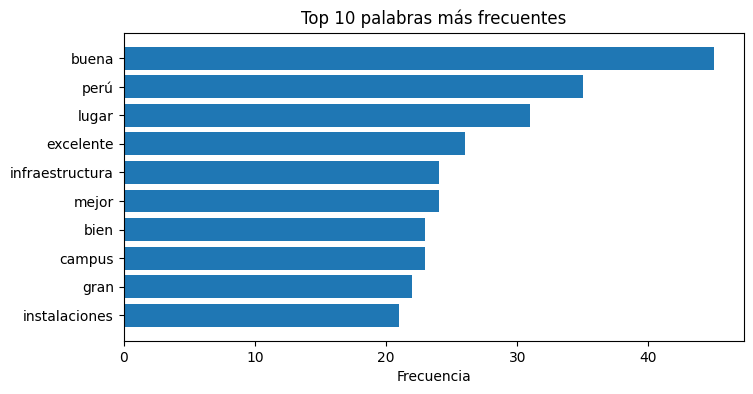

In [20]:
# Ejemplo paso a paso con un comentario
i = 0
print("Comentario original:")
print(df.loc[i, "comentario"])
print("\nTexto limpio:")
print(df.loc[i, "texto_limpio"])
print("\nSin stopwords:", df.loc[i, "tokens_sin_stopwords"])
print("Lemas:", df.loc[i, "lemas"])
print("Stems:", df.loc[i, "stems"])

# Top 10 palabras más frecuentes en todos los comentarios
todas = [p for lista in df["tokens_sin_stopwords"] for p in lista]
frecuencia = Counter(todas).most_common(10)

print("\nTop 10 palabras más frecuentes (todos los comentarios):")
for palabra, freq in frecuencia:
    print(f"  {palabra}: {freq}")

palabras, freqs = zip(*frecuencia)
plt.figure(figsize=(8, 4))
plt.barh(palabras[::-1], freqs[::-1])
plt.title("Top 10 palabras más frecuentes")
plt.xlabel("Frecuencia")
plt.show()

---
## Fase 3: Técnicas de PLN

Con los comentarios limpios aplicamos tres técnicas. Cada una responde una pregunta distinta:

1. **Análisis de sentimiento:** ¿los comentarios son positivos, negativos o neutros?
2. **TF-IDF:** ¿qué palabras caracterizan a cada universidad?
3. **Modelado de temas (NMF):** ¿de qué hablan los estudiantes en general?

### Técnica 1: Análisis de Sentimiento

Queremos saber si cada comentario tiene un tono positivo, negativo o neutro, y comparar cómo se ven las universidades entre sí.

Usamos `pysentimiento`, un modelo entrenado con textos en español que clasifica en tres categorías (POS, NEG, NEU) y da una probabilidad para cada una. Se aplica al comentario **original**, sin quitar stopwords, porque palabras como "no" cambian el sentido.

Como las reseñas de Google Maps traen estrellas, además comparamos el resultado del modelo con ellas para ver si coinciden.

In [21]:
ETIQUETAS_SENT = {"POS": "Positivo", "NEG": "Negativo", "NEU": "Neutro"}

def analizar_sentimiento(textos: list, analizador) -> tuple:
    fragmentos = [t[:512] for t in textos]          # límite del modelo
    resultados = analizador.predict(fragmentos)
    etiquetas  = [ETIQUETAS_SENT.get(r.output, r.output) for r in resultados]
    confianzas = [round(max(r.probas.values()) * 100, 1) for r in resultados]
    return etiquetas, confianzas

df["sentimiento"], df["confianza"] = analizar_sentimiento(
    df["comentario"].tolist(), analizador_sentimiento
)

print("Sentimiento de todos los comentarios:")
print(df["sentimiento"].value_counts())
df[["universidad", "comentario", "sentimiento", "confianza"]].head()

Map:   0%|          | 0/198 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Sentimiento de todos los comentarios:
sentimiento
Positivo    141
Neutro       29
Negativo     28
Name: count, dtype: int64


,universidad,comentario,sentimiento,confianza
0,Universidad de Lima,Me sorprendió después de bastante tiempo en qu...,Positivo,95.7
1,Universidad de Lima,Una universidad prestigiosa. Tiene una amplia ...,Positivo,81.9
2,Universidad de Lima,"Cambió mucho su forma de acceso, ya no existen...",Neutro,64.2
3,Universidad de Lima,Un ambiente de estudio que busca darles a los ...,Positivo,97.1
4,Universidad de Lima,"Excelentes ambientes, comodidad y excelentes d...",Positivo,96.0


sentimiento                                       Negativo  Neutro  Positivo
universidad                                                                 
Pontificia Universidad Católica del Perú (PUCP)       10.0    10.0      80.0
Universidad ESAN                                      15.0    15.0      70.0
Universidad Nacional Agraria La Molina (UNALM)         3.3    30.0      66.7
Universidad Nacional Mayor de San Marcos (UNMSM)      26.7    16.7      56.7
Universidad Nacional de Ingeniería (UNI)              10.3     3.4      86.2
Universidad Peruana Cayetano Heredia                  30.0     0.0      70.0
Universidad de Lima                                   15.8    21.1      63.2
Universidad del Pacífico                               5.0    20.0      75.0


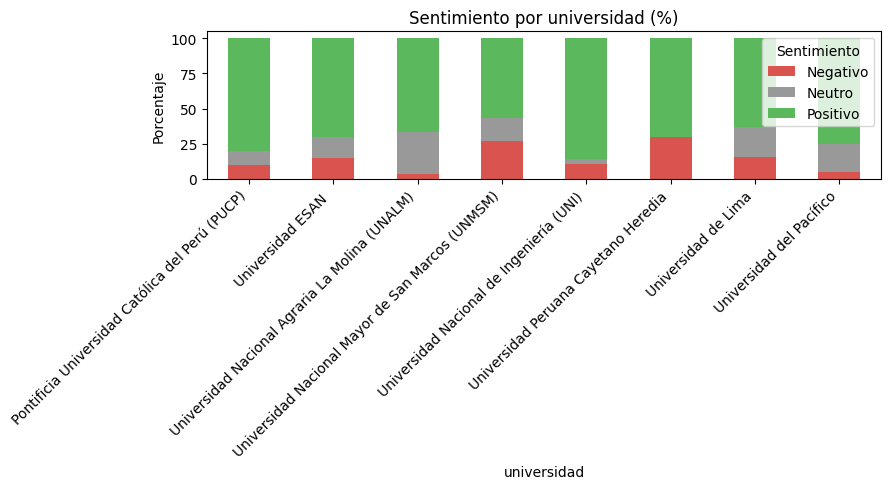


Promedio de estrellas según el sentimiento detectado:
sentimiento
Negativo    2.92
Neutro      3.92
Positivo    4.67
Name: estrellas, dtype: float64


In [22]:
# Porcentaje de cada sentimiento por universidad
tabla = pd.crosstab(df["universidad"], df["sentimiento"], normalize="index") * 100
print(tabla.round(1))

tabla.plot(kind="bar", stacked=True, figsize=(9, 5), color=["#d9534f", "#999999", "#5cb85c"][:len(tabla.columns)])
plt.title("Sentimiento por universidad (%)")
plt.ylabel("Porcentaje")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Sentimiento")
plt.tight_layout()
plt.show()

# Comparación con las estrellas (solo filas que tienen estrellas)
df["estrellas"] = pd.to_numeric(df["estrellas"], errors="coerce")
if df["estrellas"].notna().any():
    print("\nPromedio de estrellas según el sentimiento detectado:")
    print(df.groupby("sentimiento")["estrellas"].mean().round(2))

### Técnica 2: TF-IDF

TF-IDF da un puntaje a cada palabra. Una palabra tiene puntaje alto cuando **aparece mucho en una universidad pero poco en las demás**. Así encontramos qué caracteriza a cada una (por ejemplo, "laboratorio" en una, "estacionamiento" en otra).

Juntamos todos los comentarios de cada universidad en un solo texto y calculamos el TF-IDF. Las palabras que aparecen en casi todas las universidades se descartan porque no las distinguen.

Palabras que más caracterizan a cada universidad:

Pontificia Universidad Católica del Perú (PUCP): verde, lugar, área, comunidad, limpio
Universidad ESAN : ayudar, esan, laboral, excepcional, mba
Universidad Nacional Agraria La Molina (UNALM): producto, ingeniería, planta, jardinería, súper
Universidad Nacional Mayor de San Marcos (UNMSM): san, marcos, ciudad, universitaria, américa
Universidad Nacional de Ingeniería (UNI): uni, profesional, ingeniería, gustar, exigencia
Universidad Peruana Cayetano Heredia: medicina, malo, investigación, dejar, afuero
Universidad de Lima: lima, estacionamiento, sorprender, subterráneo, apoyar
Universidad del Pacífico: economía, finanza, up, clasismo, exigente


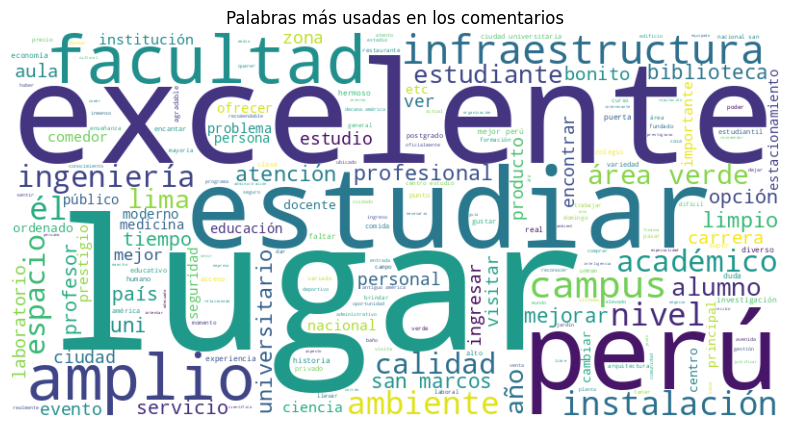

In [23]:
# Un texto por universidad
docs_uni = df.groupby("universidad")["texto_proc"].apply(lambda x: " ".join(x))

tfidf = TfidfVectorizer(max_df=0.8)
matriz = tfidf.fit_transform(docs_uni)
palabras = tfidf.get_feature_names_out()

# Top 5 palabras de cada universidad
print("Palabras que más caracterizan a cada universidad:\n")
for i, uni in enumerate(docs_uni.index):
    puntajes = matriz[i].toarray().flatten()
    top = puntajes.argsort()[::-1][:5]
    print(f"{uni}: {', '.join(palabras[j] for j in top)}")

# Nube de palabras general
nube = WordCloud(width=800, height=400, background_color="white").generate(" ".join(df["texto_proc"]))
plt.figure(figsize=(10, 5))
plt.imshow(nube, interpolation="bilinear")
plt.axis("off")
plt.title("Palabras más usadas en los comentarios")
plt.show()

### Técnica 3: Modelado de temas (NMF)

El modelado de temas agrupa los comentarios según las palabras que suelen aparecer juntas. Por ejemplo, si "profesor", "clase" y "enseñar" aparecen juntas, forman un tema que podemos llamar "Docentes".

Usamos NMF sobre los comentarios con TF-IDF. El modelo nos da las palabras de cada tema y **nosotros les ponemos el nombre** al revisarlas.

In [24]:
N_TEMAS = 4   # si tienen pocos comentarios (prueba), usar 2 o 3

vectorizador = TfidfVectorizer(min_df=2, max_df=0.9)
X = vectorizador.fit_transform(df["texto_proc"])
vocabulario = vectorizador.get_feature_names_out()

modelo_nmf = NMF(n_components=N_TEMAS, random_state=42)
pesos = modelo_nmf.fit_transform(X)

# Palabras principales de cada tema
print("Temas encontrados:\n")
for k, comp in enumerate(modelo_nmf.components_):
    top = comp.argsort()[::-1][:8]
    print(f"Tema {k+1}: {', '.join(vocabulario[j] for j in top)}")

# Tema dominante de cada comentario
df["tema"] = pesos.argmax(axis=1) + 1
print("\nCantidad de comentarios por tema:")
print(df["tema"].value_counts().sort_index())

Temas encontrados:

Tema 1: amplio, infraestructura, verde, área, espacio, ambiente, campus, seguridad
Tema 2: lugar, bonito, hermoso, estudiar, visita, seguro, ver, puerta
Tema 3: perú, mejor, facultad, ingeniería, uni, nivel, calidad, medicina
Tema 4: excelente, estudiar, profesor, docente, calidad, instalación, atención, educativo

Cantidad de comentarios por tema:
tema
1    50
2    56
3    67
4    25
Name: count, dtype: int64


nombre_tema                                       Ambiente y seguridad del campus  \
universidad                                                                         
Pontificia Universidad Católica del Perú (PUCP)                              33.3   
Universidad ESAN                                                             15.0   
Universidad Nacional Agraria La Molina (UNALM)                               43.3   
Universidad Nacional Mayor de San Marcos (UNMSM)                             13.3   
Universidad Nacional de Ingeniería (UNI)                                     31.0   
Universidad Peruana Cayetano Heredia                                         30.0   
Universidad de Lima                                                          42.1   
Universidad del Pacífico                                                     15.0   

nombre_tema                                       Docentes y servicio educativo  \
universidad                                                       

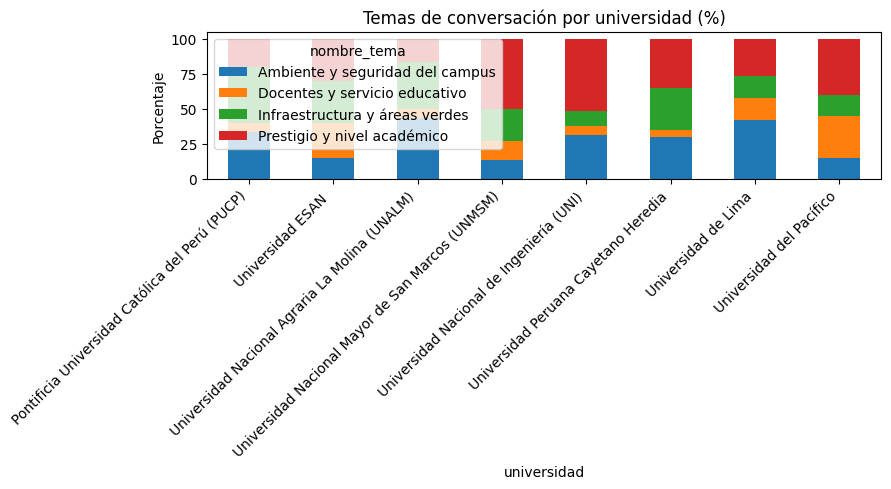

In [28]:
NOMBRES_TEMAS = {
    1: "Infraestructura y áreas verdes",
    2: "Ambiente y seguridad del campus",
    3: "Prestigio y nivel académico",
    4: "Docentes y servicio educativo",
}
df["nombre_tema"] = df["tema"].map(NOMBRES_TEMAS)

tabla_temas = pd.crosstab(df["universidad"], df["nombre_tema"], normalize="index") * 100
print(tabla_temas.round(1))

tabla_temas.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Temas de conversación por universidad (%)")
plt.ylabel("Porcentaje")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

---
## Resultados consolidados

In [26]:
print("=" * 55)
print(" RESUMEN FINAL DEL ANÁLISIS")
print("=" * 55)

print(f"\nTotal de comentarios analizados: {len(df)}")
print(f"Universidades analizadas       : {df['universidad'].nunique()}")

print("\nSentimiento general:")
print((df["sentimiento"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

print("\nUniversidad con más comentarios positivos:")
pos = (df["sentimiento"] == "Positivo").groupby(df["universidad"]).mean() * 100
print(f"  {pos.idxmax()} ({pos.max():.1f}%)")

print("\nUniversidad con más comentarios negativos:")
neg = (df["sentimiento"] == "Negativo").groupby(df["universidad"]).mean() * 100
print(f"  {neg.idxmax()} ({neg.max():.1f}%)")

print("\nTema más frecuente:")
print(f"  {df['nombre_tema'].value_counts().idxmax()}")

print("\n" + "=" * 55)

 RESUMEN FINAL DEL ANÁLISIS

Total de comentarios analizados: 198
Universidades analizadas       : 8

Sentimiento general:
sentimiento
Positivo    71.2 %
Neutro      14.6 %
Negativo    14.1 %
Name: proportion, dtype: object

Universidad con más comentarios positivos:
  Universidad Nacional de Ingeniería (UNI) (86.2%)

Universidad con más comentarios negativos:
  Universidad Peruana Cayetano Heredia (30.0%)

Tema más frecuente:
  Tema 3



In [27]:
df[["id", "universidad", "comentario", "estrellas", "fuente",
    "sentimiento", "confianza", "nombre_tema"]].to_csv("resultados_analisis.csv", index=False)

print("archivo guardado: resultados_analisis.csv")

archivo guardado: resultados_analisis.csv


---
## Conclusiones

El proyecto cumplió el objetivo planteado: a partir de 198 comentarios de estudiantes sobre 8 universidades peruanas, logramos procesar y analizar la información de forma automática con tres técnicas de PLN.

**Sobre el sentimiento:** el 71.2% de los comentarios fue positivo, el 14.6% neutro y el 14.1% negativo. La universidad con mayor porcentaje de comentarios positivos fue la UNI (86.2%), seguida de la PUCP (80%). Las que tuvieron más comentarios negativos fueron la Universidad Peruana Cayetano Heredia (30%) y la UNMSM (26.7%). Al comparar con las estrellas de Google Maps. Al comparar con las estrellas de Google Maps, los comentarios clasificados como positivos tuvieron en promedio 4.67 estrellas, los neutros 3.92 y los negativos 2.92. Esto indica que el modelo de sentimiento coincide con lo que las personas calificaron, lo que respalda la calidad del análisis.

**Sobre TF-IDF:** las palabras que más caracterizaron a cada universidad coincidieron con su perfil: "ingeniería" y "exigencia" en la UNI, "medicina" e "investigación" en la Cayetano Heredia, "economía" y "finanzas" en la Universidad del Pacífico, "jardinería" y "planta" en la UNALM, y "estacionamiento" en la Universidad de Lima. También aparecieron palabras de crítica, como "malo" en la Cayetano Heredia y "clasismo" en la Universidad del Pacífico.

**Sobre los temas:** el modelo encontró 4 temas: infraestructura y áreas verdes, ambiente y seguridad del campus, prestigio y nivel académico, y docentes y servicio educativo. El más frecuente fue "prestigio y nivel académico" (67 comentarios), sobre todo en la UNI (51.7%) y la UNMSM (50%). El tema de docentes y servicio fue el menos frecuente, pero destacó en la Universidad del Pacífico (30%) y ESAN (25%).

**Limitaciones que encontramos:**
- La muestra es pequeña (entre 20 y 30 comentarios por universidad) y se recolectó a mano, por lo que cada comentario cambia mucho los porcentajes y no representa a todos los estudiantes.
- En Google Maps suelen opinar más las personas muy contentas o muy molestas, lo que puede explicar que haya tantos comentarios positivos.
- El modelo de sentimiento puede fallar con sarcasmo o con jerga peruana.
- Los temas dependen de la cantidad de comentarios y de las palabras que se quitaron como stopwords; los nombres de los temas los asignamos nosotros.

**Qué se podría mejorar:**
- Recolectar más comentarios y de más fuentes (redes sociales, foros).
- Agregar más universidades y comparar por carrera.
- Probar modelos más avanzados para los temas.
- Guardar los resultados para ver cómo cambian las opiniones con el tiempo.